In [1]:
%pip -q install rdkit requests pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 20.4 MB/s eta 0:00:00


Retrieve and check the parent structure

,Parent_ID,PubChem_CID,Source_SMILES,RDKit_canonical_SMILES,Molecular_formula,InChIKey,RDKit_version,Retrieved_UTC,Source_URL,Automated_checks,Manual_literature_review
0,TRYPTANTHRIN_PARENT,73549,C1=CC=C2C(=C1)C(=O)N3C4=CC=CC=C4C(=O)C3=N2,O=C1c2ccccc2-n2c1nc1ccccc1c2=O,C15H8N2O2,VQQVWGVXDIPORV-UHFFFAOYSA-N,2026.09.1,20261020T034709468999Z,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,PASS,PENDING


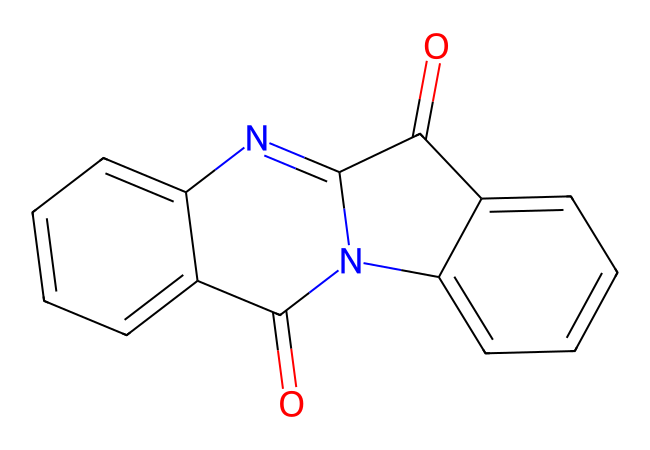

Automated structure checks: PASS

RDKit canonical SMILES: O=C1c2ccccc2-n2c1nc1ccccc1c2=O
Molecular formula: C15H8N2O2
InChIKey: VQQVWGVXDIPORV-UHFFFAOYSA-N

Manual comparison with a published structure remains pending.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json

import pandas as pd
import requests
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Separate output folder for each run.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_dir = Path("parent_verification") / run_id
output_dir.mkdir(parents=True, exist_ok=False)

# PubChem identifies tryptanthrin as CID 73549.
cid = 73549
url = (
    f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}"
    "/property/CanonicalSMILES,InChIKey,MolecularFormula/JSON"
)

response = requests.get(url, timeout=60)
response.raise_for_status()
source_data = response.json()

# Preserve the original downloaded record.
(output_dir / "pubchem_source.json").write_text(
    json.dumps(source_data, indent=2),
    encoding="utf-8"
)

record = source_data["PropertyTable"]["Properties"][0]
assert record["CID"] == cid, "Unexpected compound ID."

# Support both newer and older PubChem field names.
source_smiles = (
    record.get("ConnectivitySMILES")
    or record.get("CanonicalSMILES")
    or record.get("SMILES")
)
assert source_smiles, f"SMILES missing. Returned fields: {list(record)}"

mol = Chem.MolFromSmiles(source_smiles)
assert mol is not None, "RDKit could not read the structure."
Chem.SanitizeMol(mol)

canonical_smiles = Chem.MolToSmiles(
    mol, canonical=True, isomericSmiles=True
)
formula = rdMolDescriptors.CalcMolFormula(mol)
inchikey = Chem.MolToInchiKey(mol)

assert formula == record["MolecularFormula"] == "C15H8N2O2", \
    "Molecular formula mismatch."
assert inchikey == record["InChIKey"], "InChIKey mismatch."
assert len(Chem.GetMolFrags(mol)) == 1, \
    "Unexpected disconnected structure."
assert Chem.GetFormalCharge(mol) == 0, \
    "Unexpected formal charge."

# Check that the saved SMILES reconstructs the same identity.
reloaded = Chem.MolFromSmiles(canonical_smiles)
assert reloaded is not None
assert Chem.MolToInchiKey(reloaded) == inchikey

result = {
    "Parent_ID": "TRYPTANTHRIN_PARENT",
    "PubChem_CID": cid,
    "Source_SMILES": source_smiles,
    "RDKit_canonical_SMILES": canonical_smiles,
    "Molecular_formula": formula,
    "InChIKey": inchikey,
    "RDKit_version": rdBase.rdkitVersion,
    "Retrieved_UTC": run_id,
    "Source_URL": url,
    "Automated_checks": "PASS",
    "Manual_literature_review": "PENDING"
}

table = pd.DataFrame([result])
table.to_csv(output_dir / "parent_verification.csv", index=False)

Chem.MolToMolFile(mol, str(output_dir / "parent.mol"))
structure_image = Draw.MolToImage(mol, size=(650, 450))
structure_image.save(output_dir / "parent_structure.png")

display(table)
display(structure_image)

print("Automated structure checks: PASS")
print("\nRDKit canonical SMILES:", canonical_smiles)
print("Molecular formula:", formula)
print("InChIKey:", inchikey)
print("\nManual comparison with a published structure remains pending.")

Download your outputs

In [3]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    f"/content/parent_verification_{run_id}",
    "zip",
    root_dir=str(output_dir)
)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

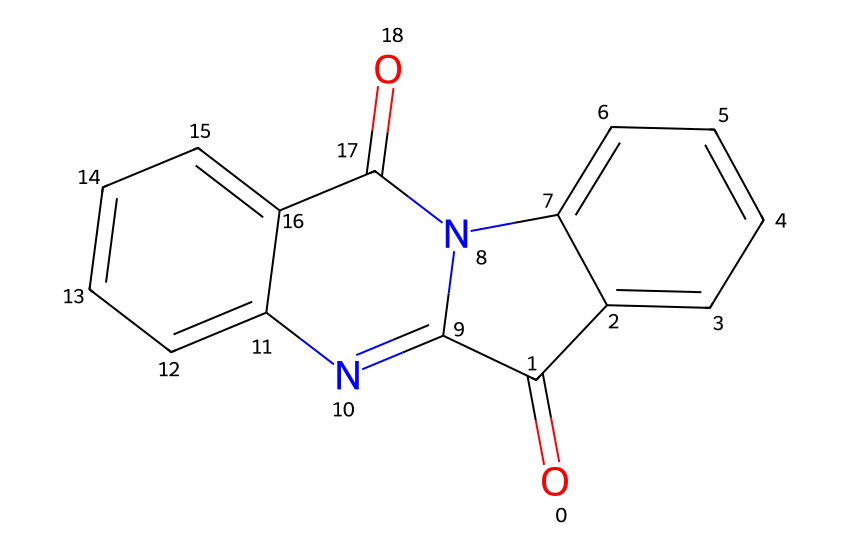

In [4]:
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None, "Parent structure could not be read."

drawer = rdMolDraw2D.MolDraw2DSVG(850, 550)
drawer.drawOptions().addAtomIndices = True
drawer.DrawMolecule(parent)
drawer.FinishDrawing()

display(SVG(drawer.GetDrawingText()))

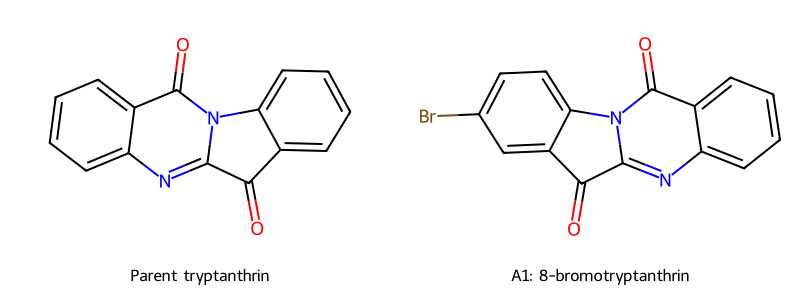

Analog SMILES: O=C1c2cc(Br)ccc2-n2c1nc1ccccc1c2=O
Formula: C15H7BrN2O2
Structure and scaffold checks: PASS


In [5]:
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Keep this exact SMILES so the atom-index mapping stays consistent.
parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None

c8_index = 4
site = parent.GetAtomWithIdx(c8_index)

assert site.GetSymbol() == "C"
assert site.GetIsAromatic()
assert site.GetTotalNumHs() == 1, "Expected one replaceable hydrogen."

# Attach Br. RDKit updates the implicit hydrogen during sanitization.
editable = Chem.RWMol(parent)
br_index = editable.AddAtom(Chem.Atom("Br"))
editable.AddBond(c8_index, br_index, Chem.BondType.SINGLE)

analog = editable.GetMol()
Chem.SanitizeMol(analog)

assert rdMolDescriptors.CalcMolFormula(analog) == "C15H7BrN2O2"
assert analog.HasSubstructMatch(parent), "Parent scaffold check failed."

analog_smiles = Chem.MolToSmiles(analog, canonical=True)

display(Draw.MolsToGridImage(
    [parent, analog],
    legends=["Parent tryptanthrin", "A1: 8-bromotryptanthrin"],
    molsPerRow=2,
    subImgSize=(400, 300)
))

print("Analog SMILES:", analog_smiles)
print("Formula:", rdMolDescriptors.CalcMolFormula(analog))
print("Structure and scaffold checks: PASS")

,Reference_ID,Source_compound_ID,SMILES,Modified_site,Substituent,Modification_type,Molecular_formula,Source_DOI,Source_location,Status,Automated_checks
0,Gao2021_A1,A1,O=C1c2cc(Br)ccc2-n2c1nc1ccccc1c2=O,C-8,Br,Ring hydrogen substitution,C15H7BrN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
1,Gao2021_A2,A2,O=C1c2cc(I)ccc2-n2c1nc1ccccc1c2=O,C-8,I,Ring hydrogen substitution,C15H7IN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
2,Gao2021_A3,A3,O=C1c2cc(Cl)ccc2-n2c1nc1ccccc1c2=O,C-8,Cl,Ring hydrogen substitution,C15H7ClN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
3,Gao2021_A4,A4,O=C1c2cc(F)ccc2-n2c1nc1ccccc1c2=O,C-8,F,Ring hydrogen substitution,C15H7FN2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
4,Gao2021_A5,A5,Cc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,C-8,CH3,Ring hydrogen substitution,C16H10N2O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
5,Gao2021_A6,A6,O=C1c2cc([N+](=O)[O-])ccc2-n2c1nc1ccccc1c2=O,C-8,NO2,Ring hydrogen substitution,C15H7N3O4,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS
6,Gao2021_A7,A7,Nc1ccc2c(c1)C(=O)c1nc3ccccc3c(=O)n1-2,C-8,NH2,Ring hydrogen substitution,C15H9N3O2,10.3390/biomedicines9111527,"Figure 1B, page 2",Published reference reconstruction,PASS


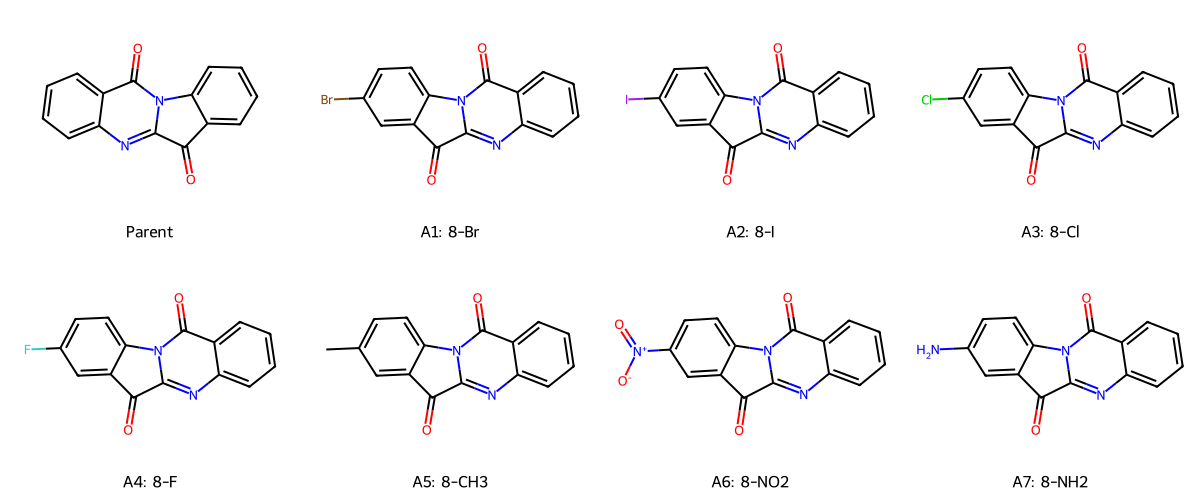

Generated: 7 reference derivatives
Formula, scaffold, connectivity and uniqueness checks: PASS


In [6]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display

# Atom index 4 maps to C-8 ONLY for this exact parent SMILES.
parent_smiles = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
parent = Chem.MolFromSmiles(parent_smiles)
assert parent is not None
c8_index = 4

# First atom in each fragment is the atom attached to C-8.
rules = [
    ("A1", "Br",  "Br",            "C15H7BrN2O2"),
    ("A2", "I",   "I",             "C15H7IN2O2"),
    ("A3", "Cl",  "Cl",            "C15H7ClN2O2"),
    ("A4", "F",   "F",             "C15H7FN2O2"),
    ("A5", "CH3", "C",             "C16H10N2O2"),
    ("A6", "NO2", "[N+](=O)[O-]",  "C15H7N3O4"),
    ("A7", "NH2", "N",             "C15H9N3O2"),
]

molecules, rows = [], []

for compound_id, substituent, fragment_smiles, expected_formula in rules:
    fragment = Chem.MolFromSmiles(fragment_smiles)
    assert fragment is not None

    combined = Chem.CombineMols(parent, fragment)
    editable = Chem.RWMol(combined)

    # Fragment atom 0 follows the last parent atom.
    attachment_index = parent.GetNumAtoms()
    editable.AddBond(
        c8_index, attachment_index, Chem.BondType.SINGLE
    )

    analog = editable.GetMol()
    Chem.SanitizeMol(analog)

    formula = rdMolDescriptors.CalcMolFormula(analog)
    assert formula == expected_formula, f"{compound_id}: formula mismatch"
    assert analog.HasSubstructMatch(parent), \
        f"{compound_id}: scaffold mismatch"
    assert len(Chem.GetMolFrags(analog)) == 1
    assert Chem.GetFormalCharge(analog) == 0

    smiles = Chem.MolToSmiles(analog, canonical=True)
    molecules.append(analog)

    rows.append({
        "Reference_ID": f"Gao2021_{compound_id}",
        "Source_compound_ID": compound_id,
        "SMILES": smiles,
        "Modified_site": "C-8",
        "Substituent": substituent,
        "Modification_type": "Ring hydrogen substitution",
        "Molecular_formula": formula,
        "Source_DOI": "10.3390/biomedicines9111527",
        "Source_location": "Figure 1B, page 2",
        "Status": "Published reference reconstruction",
        "Automated_checks": "PASS",
    })

reference_library = pd.DataFrame(rows)
assert reference_library["SMILES"].is_unique, "Duplicate structures found."

display(reference_library)
display(Draw.MolsToGridImage(
    [parent] + molecules,
    legends=["Parent"] + [
        f"{r[0]}: 8-{r[1]}" for r in rules
    ],
    molsPerRow=4,
    subImgSize=(300, 250)
))

print(f"Generated: {len(reference_library)} reference derivatives")
print("Formula, scaffold, connectivity and uniqueness checks: PASS")

In [7]:
from google.colab import files

filename = "Gao2021_C8_reference_batch.csv"
reference_library.to_csv(filename, index=False)
files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>